Importing dataset

In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing

sns.set_style("whitegrid")

Loading Dataset

In [49]:
housing = fetch_california_housing(as_frame=True)

df = housing.frame

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [50]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=df)

https://docs.google.com/spreadsheets/d/10UmHb8uzg5dvx-0AkBQk_Y1kSkvzmUrCGugY9xHJa5k/edit#gid=0


In [51]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (20640, 9)

Column names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']


In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [53]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [54]:
df.isnull().sum()

,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


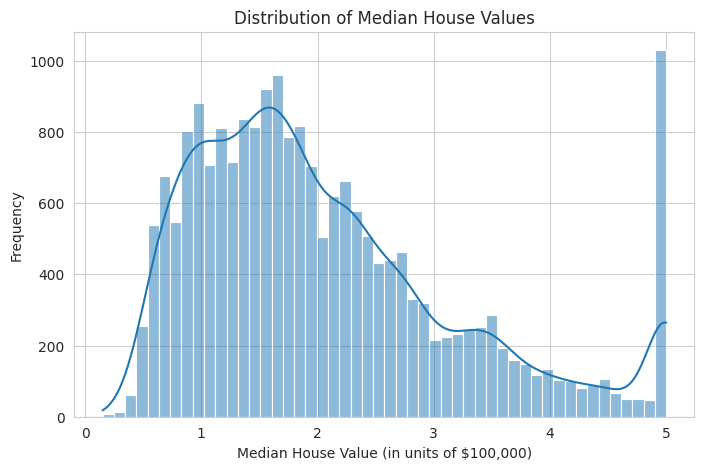

In [55]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="MedHouseVal",
    bins=50,
    kde=True
)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value (in units of $100,000)")
plt.ylabel("Frequency")

plt.show()

Exploring relationship of median incomw vs median house value

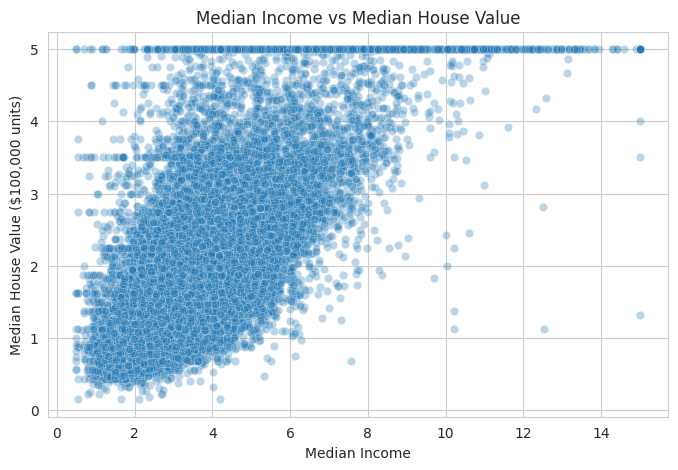

In [56]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="MedInc",
    y="MedHouseVal",
    alpha=0.3
)

plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value ($100,000 units)")

plt.show()

In [57]:
X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

In [58]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (20640, 8)
y shape: (20640,)


Train Test Split

In [59]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [60]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16512, 8)
X_test: (4128, 8)
y_train: (16512,)
y_test: (4128,)


In [61]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

Checking the values learned by model

In [62]:
print("Intercept:", model.intercept_)
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coefficients

Intercept: -37.02327770606405


,Feature,Coefficient
0,MedInc,0.448675
1,HouseAge,0.009724
2,AveRooms,-0.123323
3,AveBedrms,0.783145
4,Population,-0.000002
5,AveOccup,-0.003526
6,Latitude,-0.419792
7,Longitude,-0.433708


In [63]:
y_pred = model.predict(X_test)
comparison = pd.DataFrame({
    "Actual": y_test.values[:10],
    "Predicted": y_pred[:10]
})

comparison

,Actual,Predicted
0,0.47700,0.719123
1,0.45800,1.764017
2,5.00001,2.709659
3,2.18600,2.838926
4,2.78000,2.604657
5,1.58700,2.011754
6,1.98200,2.645500
7,1.57500,2.168755
8,3.40000,2.740746
9,4.46600,3.915615


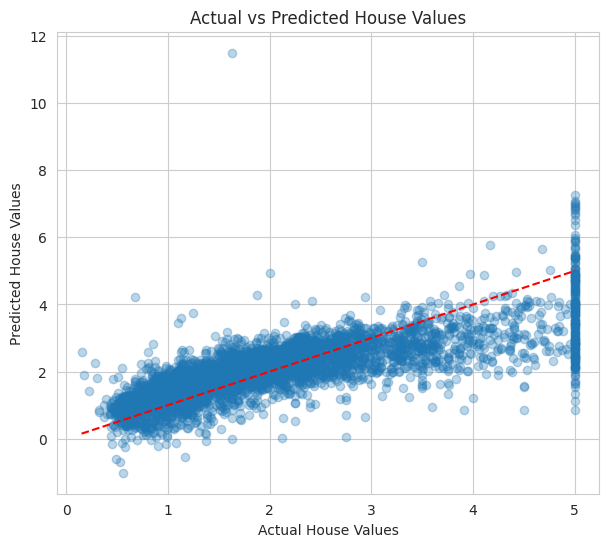

In [64]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.3)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Actual vs Predicted House Values")

plt.show()

The closer the dots are to the diagnal line, the closer the predicted to the actual values

In [65]:
comparison["Error"] = comparison["Actual"] - comparison["Predicted"]

comparison
comparison["Absolute Error"] = abs(comparison["Error"])

comparison

,Actual,Predicted,Error,Absolute Error
0,0.47700,0.719123,-0.242123,0.242123
1,0.45800,1.764017,-1.306017,1.306017
2,5.00001,2.709659,2.290351,2.290351
3,2.18600,2.838926,-0.652926,0.652926
4,2.78000,2.604657,0.175343,0.175343
5,1.58700,2.011754,-0.424754,0.424754
6,1.98200,2.645500,-0.663500,0.663500
7,1.57500,2.168755,-0.593755,0.593755
8,3.40000,2.740746,0.659254,0.659254
9,4.46600,3.915615,0.550385,0.550385


Mean Absolute error(MAE)

In [66]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_pred)

print("MAE:", mae)

MAE: 0.5332001304956561


Mean Squared Error(MSE)

In [67]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, y_pred)

print("MSE:", mse)

MSE: 0.5558915986952438


Root Mean Square Error(RMSE)

In [68]:
rmse = np.sqrt(mse)

print("RMSE:", rmse)

RMSE: 0.745581383012776


R^2(Coefficient of Determination)

In [69]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)

print("R²:", r2)

R²: 0.5757877060324512


In [70]:
print(f"MAE in dollars:  ${mae * 100000:,.2f}")
print(f"RMSE in dollars: ${rmse * 100000:,.2f}")

MAE in dollars:  $53,320.01
RMSE in dollars: $74,558.14


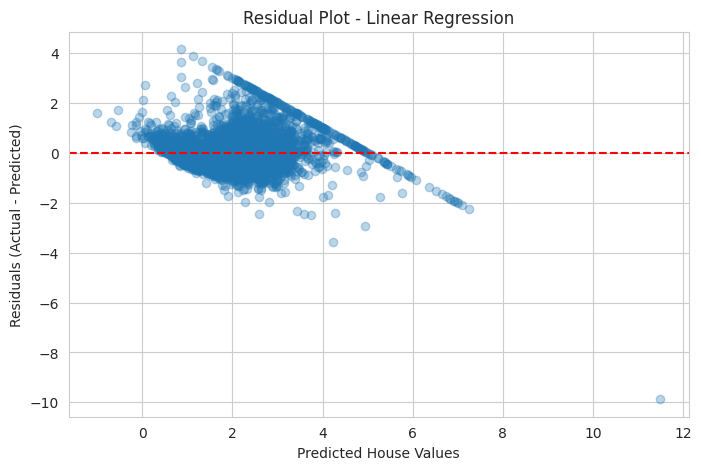

In [71]:
residuals = y_test - y_pred
plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.3)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted House Values")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot - Linear Regression")

plt.show()

Most Error Analysis

In [72]:
residual_df = X_test.copy()

residual_df["Actual"] = y_test
residual_df["Predicted"] = y_pred
residual_df["Residual"] = residuals

residual_df["Absolute_Error"] = abs(residuals)

residual_df.sort_values(
    "Absolute_Error",
    ascending=False
).head(10)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Actual,Predicted,Residual,Absolute_Error
1979,4.6250,34.0,132.533333,34.066667,36.0,2.400000,38.80,-120.08,1.62500,11.500331,-9.875331,9.875331
6688,0.4999,28.0,7.677419,1.870968,142.0,4.580645,34.15,-118.08,5.00001,0.851622,4.148388,4.148388
10574,1.9659,6.0,4.795455,1.159091,125.0,2.840909,33.72,-117.70,5.00001,1.115227,3.884783,3.884783
12389,3.7727,24.0,10.953586,1.848101,473.0,1.995781,33.75,-116.43,5.00001,1.319954,3.680056,3.680056
19542,1.7679,39.0,5.000000,0.888889,22.0,2.444444,37.63,-120.92,4.50000,0.867216,3.632784,3.632784
4548,7.5752,52.0,3.142857,1.000000,55.0,7.857143,34.02,-118.21,0.67500,4.236215,-3.561215,3.561215
459,1.1696,52.0,2.436000,0.944000,1349.0,5.396000,37.87,-122.25,5.00001,1.547530,3.452480,3.452480
15652,0.9000,52.0,2.237474,1.053535,3260.0,2.237474,37.80,-122.41,5.00001,1.642870,3.357140,3.357140
12069,4.2386,6.0,7.723077,1.169231,228.0,3.507692,33.83,-117.55,5.00001,1.668034,3.331976,3.331976
4630,2.3674,20.0,2.740554,1.047859,2919.0,2.450882,34.07,-118.31,5.00001,1.711156,3.288854,3.288854


Decision Tree Regression

In [73]:
from sklearn.tree import DecisionTreeRegressor
tree_model = DecisionTreeRegressor(random_state=42)
tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)


In [74]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

tree_mae = mean_absolute_error(y_test, tree_pred)

tree_mse = mean_squared_error(y_test, tree_pred)

tree_rmse = np.sqrt(tree_mse)

tree_r2 = r2_score(y_test, tree_pred)

print("Decision Tree Regression Results")
print("------------------------------")
print(f"MAE:  {tree_mae:.4f}")
print(f"MSE:  {tree_mse:.4f}")
print(f"RMSE: {tree_rmse:.4f}")
print(f"R²:   {tree_r2:.4f}")

print(f"\nMAE in dollars:  ${tree_mae * 100000:,.2f}")
print(f"RMSE in dollars: ${tree_rmse * 100000:,.2f}")

Decision Tree Regression Results
------------------------------
MAE:  0.4547
MSE:  0.4952
RMSE: 0.7037
R²:   0.6221

MAE in dollars:  $45,467.92
RMSE in dollars: $70,372.95


To check if overfitting is happening on the test set

In [75]:
train_pred = tree_model.predict(X_train)

train_r2 = r2_score(y_train, train_pred)
test_r2 = r2_score(y_test, tree_pred)

print("Training R²:", train_r2)
print("Testing R²:", test_r2)

Training R²: 1.0
Testing R²: 0.622075845135081


The decision tree is overfitting

In [76]:
depths = [1, 2, 3, 5, 10, 15, 20, None]

depth_results = []

for depth in depths:

    model_depth = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    model_depth.fit(X_train, y_train)

    train_prediction = model_depth.predict(X_train)
    test_prediction = model_depth.predict(X_test)

    depth_results.append({
        "Depth": str(depth),
        "Train R2": r2_score(y_train, train_prediction),
        "Test R2": r2_score(y_test, test_prediction),
        "Test MAE": mean_absolute_error(y_test, test_prediction),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_prediction))
    })

depth_df = pd.DataFrame(depth_results)

depth_df.round(4)

,Depth,Train R2,Test R2,Test MAE,Test RMSE
0,1,0.3170,0.2795,0.7524,0.9717
1,2,0.4520,0.4244,0.6601,0.8685
2,3,0.5379,0.5098,0.5978,0.8015
3,5,0.6377,0.5997,0.5223,0.7242
4,10,0.8348,0.6829,0.4332,0.6446
5,15,0.9607,0.6460,0.4375,0.6811
6,20,0.9957,0.6268,0.4494,0.6994
7,None,1.0000,0.6221,0.4547,0.7037


Depth of 10 is optimal

In [77]:
best_tree = DecisionTreeRegressor(
    max_depth=10,
    random_state=42
)

best_tree.fit(X_train, y_train)

best_tree_pred = best_tree.predict(X_test)
print("Decision Tree (Depth 10)")
print("----------------------")

print("R²:", r2_score(y_test, best_tree_pred))

print("MAE:", mean_absolute_error(y_test, best_tree_pred))

print("RMSE:", np.sqrt(mean_squared_error(y_test, best_tree_pred)))

Decision Tree (Depth 10)
----------------------
R²: 0.6829476865157171
MAE: 0.4332031802610876
RMSE: 0.6445682261497634


Visualising the tree

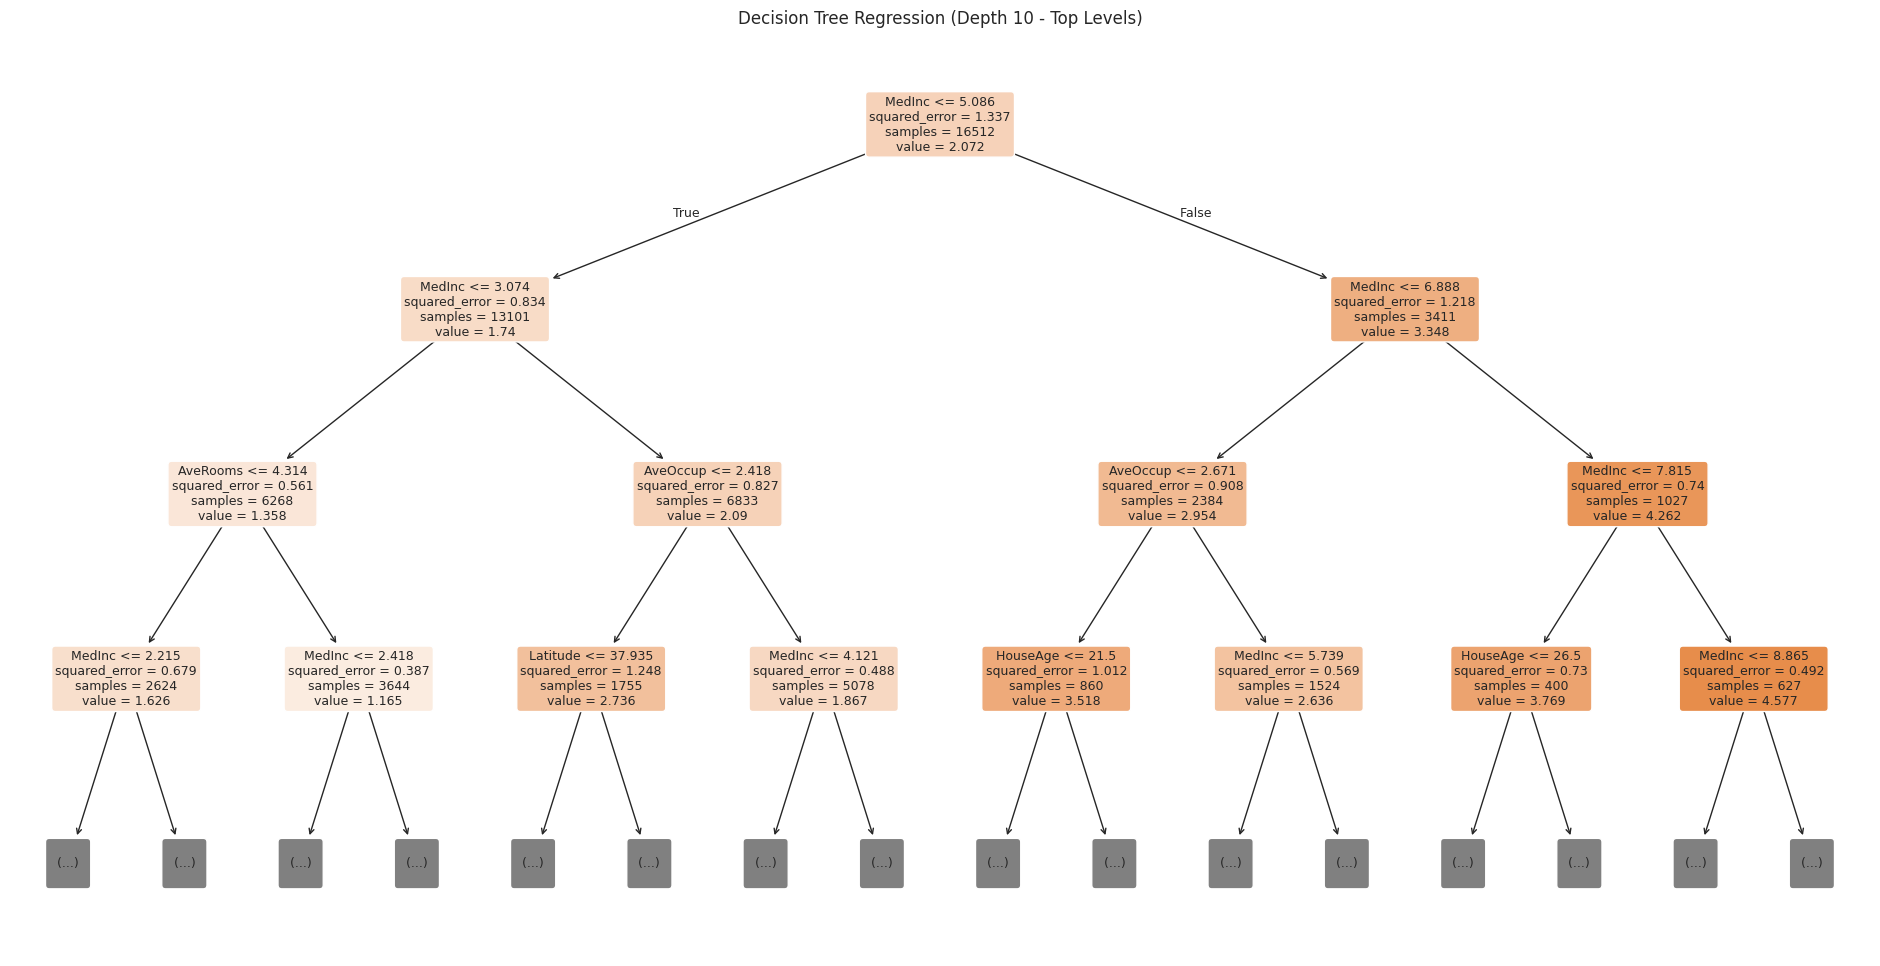

In [78]:
from sklearn.tree import plot_tree

plt.figure(figsize=(24, 12))

plot_tree(
    best_tree,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Decision Tree Regression (Depth 10 - Top Levels)")
plt.show()

Random Forest

In [79]:
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)


In [80]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_mae = mean_absolute_error(y_test, rf_pred)

rf_mse = mean_squared_error(y_test, rf_pred)

rf_rmse = np.sqrt(rf_mse)

rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Regression Results")
print("------------------------------")
print(f"MAE:  {rf_mae:.4f}")
print(f"MSE:  {rf_mse:.4f}")
print(f"RMSE: {rf_rmse:.4f}")
print(f"R²:   {rf_r2:.4f}")

print(f"\nMAE in dollars:  ${rf_mae * 100000:,.2f}")
print(f"RMSE in dollars: ${rf_rmse * 100000:,.2f}")

Random Forest Regression Results
------------------------------
MAE:  0.3315
MSE:  0.2493
RMSE: 0.4993
R²:   0.8098

MAE in dollars:  $33,145.08
RMSE in dollars: $49,926.75


In [81]:
rf_train_pred = rf_model.predict(X_train)

rf_train_r2 = r2_score(y_train, rf_train_pred)
rf_test_r2 = r2_score(y_test, rf_pred)

print("Random Forest Training R²:", rf_train_r2)
print("Random Forest Testing R²:", rf_test_r2)

Random Forest Training R²: 0.9741038516646139
Random Forest Testing R²: 0.8097784566224351


Feature Importance

In [82]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance

,Feature,Importance
0,MedInc,0.356523
6,Latitude,0.130046
5,AveOccup,0.125169
7,Longitude,0.124464
2,AveRooms,0.123296
1,HouseAge,0.057693
3,AveBedrms,0.047041
4,Population,0.035768


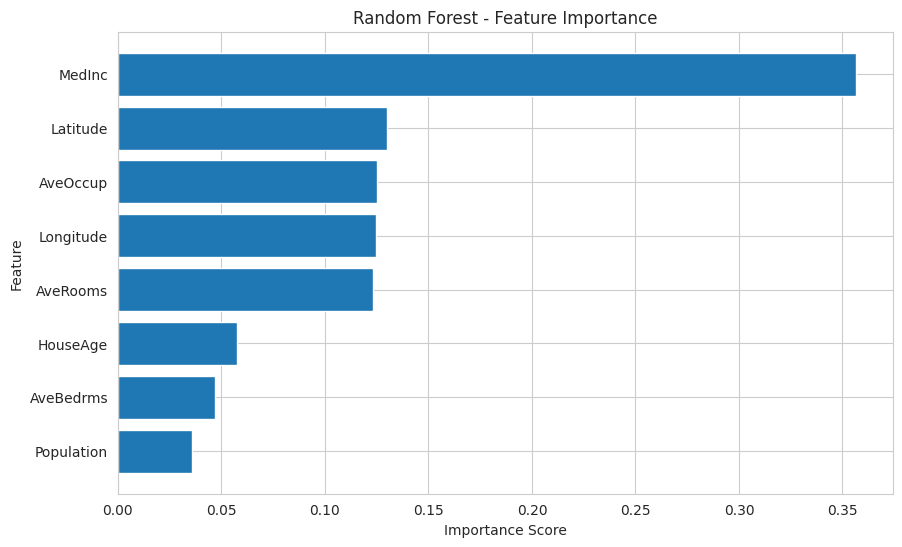

In [83]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Random Forest - Feature Importance")

plt.gca().invert_yaxis()

plt.show()

Hyperparameter tuning using 3-fold cross validation

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20, None],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt"]
}
grid_search = GridSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ),
    param_grid=param_grid,
    cv=3,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation MAE:")
print(-grid_search.best_score_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits


In [ ]:
# Get the best model found by Grid Search
tuned_rf = grid_search.best_estimator_

# Predict on the test set
tuned_pred = tuned_rf.predict(X_test)

# Calculate metrics
tuned_mae = mean_absolute_error(y_test, tuned_pred)
tuned_mse = mean_squared_error(y_test, tuned_pred)
tuned_rmse = np.sqrt(tuned_mse)
tuned_r2 = r2_score(y_test, tuned_pred)

print("Tuned Random Forest Results")
print("--------------------------")
print(f"MAE:  {tuned_mae:.4f}")
print(f"MSE:  {tuned_mse:.4f}")
print(f"RMSE: {tuned_rmse:.4f}")
print(f"R²:   {tuned_r2:.4f}")

print(f"\nMAE in dollars:  ${tuned_mae * 100000:,.2f}")
print(f"RMSE in dollars: ${tuned_rmse * 100000:,.2f}")

- 2 tree counts
- 3 depth settings
- 2 leaf-size settings
- 1 feature-selection setting

Total:
12 (Multiplication)

In [ ]:
tuned_train_pred = tuned_rf.predict(X_train)

print("Tuned RF Training R²:",
      r2_score(y_train, tuned_train_pred))

print("Tuned RF Testing R²:",
      r2_score(y_test, tuned_pred))

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, tuned_pred, alpha=0.3)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Tuned Random Forest: Actual vs Predicted")

plt.show()

Permutation Importance
(Bigger the performance drop, the more the importance of a feature)

In [ ]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    tuned_rf,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="r2"

)
perm_importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
})

perm_importance_df = perm_importance_df.sort_values(
    by="Importance",
    ascending=False
)

perm_importance_df


Using sample data to test model

In [ ]:

sample_house = pd.DataFrame([{
    "MedInc": 5.0,
    "HouseAge": 30,
    "AveRooms": 5.5,
    "AveBedrms": 1.1,
    "Population": 1200,
    "AveOccup": 3.0,
    "Latitude": 34.05,
    "Longitude": -118.25
}])


sample_house = sample_house[X_train.columns]

sample_prediction = tuned_rf.predict(sample_house)


predicted_price = sample_prediction[0] * 100000

print("Sample House Prediction")
print("---------------------")
print(f"Predicted value: ${predicted_price:,.2f}")

Inbuilt Function to run

In [ ]:
def predict_house_value(
    med_inc,
    house_age,
    ave_rooms,
    ave_bedrms,
    population,
    ave_occup,
    latitude,
    longitude
):
    house = pd.DataFrame([{
        "MedInc": med_inc,
        "HouseAge": house_age,
        "AveRooms": ave_rooms,
        "AveBedrms": ave_bedrms,
        "Population": population,
        "AveOccup": ave_occup,
        "Latitude": latitude,
        "Longitude": longitude
    }])


    house = house[X_train.columns]

    prediction = tuned_rf.predict(house)[0]

    prediction_dollars = prediction * 100000

    return prediction_dollars

Saving the model

In [ ]:
import joblib

model_artifact = {
    "model": tuned_rf,
    "features": list(X_train.columns),
    "target_scale": 100000
}

joblib.dump(model_artifact, "house_price_model.pkl")

print("Model saved successfully!")

In [ ]:
loaded_artifact = joblib.load("house_price_model.pkl")

loaded_model = loaded_artifact["model"]
feature_names = loaded_artifact["features"]
target_scale = loaded_artifact["target_scale"]

print("Model loaded successfully!")
print("Features:", feature_names)
sample_house = pd.DataFrame([{
    "MedInc": 5.0,
    "HouseAge": 30,
    "AveRooms": 5.5,
    "AveBedrms": 1.1,
    "Population": 1200,
    "AveOccup": 3.0,
    "Latitude": 34.05,
    "Longitude": -118.25
}])

sample_house = sample_house[feature_names]

prediction = loaded_model.predict(sample_house)[0] * target_scale

print(f"Prediction from loaded model: ${prediction:,.2f}")